# 1 · Low-complexity regions with Shannon entropy

The entropy of a window's residue composition, $H = -\sum_a f_a \log_2 f_a$, is 0 for a homopolymer
and at most $\log_2 \min(W, 20)$ bits. Following SEG (Wootton & Federhen, 1993), a window with
$H \le K_1$ (*trigger*) seeds a low-complexity region (LCR), which grows through neighbouring
windows with $H \le K_2$ (*extension*).

In [1]:
import matplotlib.pyplot as plt
from aarepeats import EXAMPLES, read_fasta
from aarepeats import plotting as P

P.use_style()
DATA = "../data"
seq = EXAMPLES["toy"]
print(len(seq), seq)

66 MAMAMAMAMAMAPRTEINSEQENCEAAAAAAHHHHTESTSTSTSTSTSSGSGSGSGSWWWWWGSGS


  1-12  H=1.00  MAMAMAMAMAMA
 22-66  H=2.85  ENCEAAAAAAHHHHTESTSTSTSTSTSSGSGSGSGSWWWWWGSGS


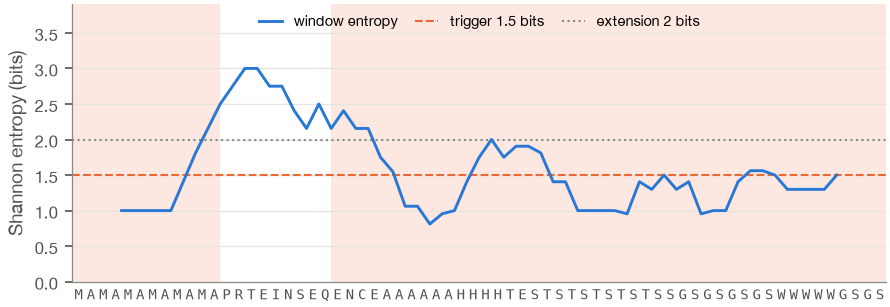

In [2]:
from aarepeats import detect_lcr

res = detect_lcr(seq, window=8, trigger=1.5, extension=2.0)
for r in res.regions:
    print(f"{r.start + 1:>3}-{r.end:<3} H={r.entropy:.2f}  {r.sequence}")
P.plot_entropy(res, seq, 1.5, 2.0)
plt.show()

## Real protein: polyQ and polyG tracts of the androgen receptor (SEG defaults W=12, 2.2/2.5 bits)

  42-99   H=2.41  PEAASAAPPGASLLLLQQQQQQQQQQQQQQQQQQQQQQQETSPRQ
 150-162  H=2.20  PAPPDEDDSAAPS
 187-217  H=3.04  EASTMQLLQQQQQEAVSEGSSSGRAREASGA
 319-341  H=2.58  GLEGESLGCSGSAAAGSSGTLEL
 368-389  H=2.43  PLALAGPPPPPPPPHPHARIKL
 409-436  H=2.64  GDLASLHGAGAAGPGSGSPSAAASSSWH
 442-483  H=1.95  EEGQLYGPCGGGGGGGGGGGGGGGGGGGGGGGEAGAVAPYGY
 642-661  H=2.73  EEGEASSTTSPTEETTQKLT


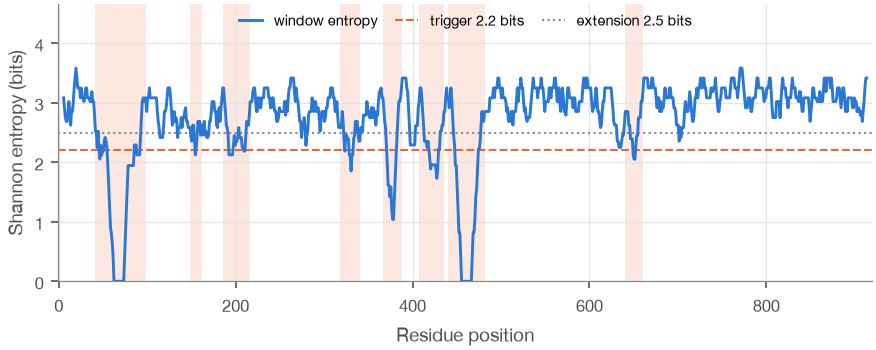

In [3]:
header, ar = read_fasta(f"{DATA}/P10275.fasta")[0]
res = detect_lcr(ar)
for r in res.regions:
    print(f"{r.start + 1:>4}-{r.end:<4} H={r.entropy:.2f}  {r.sequence[:45]}")
P.plot_entropy(res, ar, 2.2, 2.5)
plt.show()